## Introducción

Este cuaderno genera la **figura de diagrama conceptual** que ilustra la estructura molecular de las capas de líquido próximas a una pared sólida, en el contexto del efecto de reducción de difusividad que fundamenta el modelo Nano-NMR del TFM.

La figura muestra tres regiones:
1. **Capa adsorbida** (azul oscuro, $D \approx 0$): moléculas inmovilizadas por fuerzas de Van der Waals, enlaces de hidrógeno e interacciones hidrofóbicas con la superficie sólida.
2. **Capa de transición** (azul real): moléculas con movimiento restringido por obstáculos dinámicos, con $D < D_0$.
3. **Bulk** (verde): moléculas con difusividad aproximada al valor volumétrico $D \approx D_0$.

Se incluye un inset con el perfil $D(z)/D_0$ que muestra la recuperación de la difusividad con la distancia a la pared.

C:\Users\allan\AppData\Local\Temp\ipykernel_3168\3778640896.py:84: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(pad=1.5)


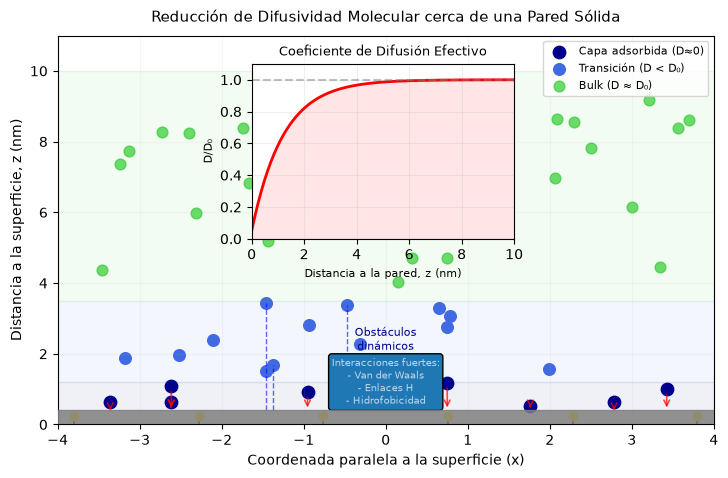

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# CONFIGURACIÓN DE FIGURA (7.5 x 5 pulgadas)
fig = plt.figure(figsize=(7.5, 5))
ax = fig.add_subplot(111)

# 1. Pared sólida (gris)
wall = Rectangle((-4, 0), 8, 0.4, color='#7f7f7f', alpha=0.85, zorder=10)
ax.add_patch(wall)

# 2. Moléculas en diferentes capas
np.random.seed(42)

# Capa adsorbida (inmóvil)
x_ads = np.random.uniform(-3.8, 3.8, 8)
z_ads = np.random.uniform(0.5, 1.2, 8)
ads = ax.scatter(x_ads, z_ads, c='darkblue', s=80, label='Capa adsorbida (D≈0)')

# Capa de transición (movimiento restringido)
x_trans = np.random.uniform(-3.5, 3.5, 15)
z_trans = np.random.uniform(1.3, 3.5, 15)
trans = ax.scatter(x_trans, z_trans, c='royalblue', s=70, label='Transición (D < D₀)')

# Bulk (movimiento libre)
x_bulk = np.random.uniform(-3.8, 3.8, 25)
z_bulk = np.random.uniform(4, 10, 25)
bulk = ax.scatter(x_bulk, z_bulk, c='limegreen', s=60, alpha=0.7, label='Bulk (D ≈ D₀)')

# 3. Fuerzas de Van der Waals
for i in range(len(x_ads)):
    ax.annotate('', 
                xy=(x_ads[i], 0.4),      # Punto final (pared)
                xytext=(x_ads[i], z_ads[i]), # Punto inicial (molécula)
                arrowprops=dict(arrowstyle='->', color='red', lw=1.2, alpha=0.7, shrinkA=4))

# 4. Enlaces de hidrógeno
for i in range(4):  # Solo para algunas moléculas
    ax.plot([x_trans[i], x_trans[i]], [0.4, z_trans[i]], 
            'b--', lw=1.0, alpha=0.6)

# 5. Grupos hidrofóbicos
for x in np.linspace(-3.8, 3.8, 6):
    ax.plot([x, x], [0, 0.25], 'k-', lw=1.2)  # Cadenas
    ax.plot(x, 0.25, 'o', markersize=6, color='gold')  # Grupo terminal

# 6. Gráfico de difusividad inserto (posición ajustada)
ax_inset = fig.add_axes([0.35, 0.5, 0.35, 0.35])  # Posición y tamaño optimizados
z_vals = np.linspace(0, 12, 100)
D_vals = 1 - 0.95*np.exp(-z_vals/1.2)
ax_inset.plot(z_vals, D_vals, 'r-', lw=2.0)
ax_inset.fill_between(z_vals, 0, D_vals, color='red', alpha=0.1)
ax_inset.axhline(y=1, color='gray', linestyle='--', alpha=0.5)
ax_inset.set_xlabel('Distancia a la pared, z (nm)', fontsize=8)
ax_inset.set_ylabel('D/D₀', fontsize=8)
ax_inset.set_title('Coeficiente de Difusión Efectivo', fontsize=9)
ax_inset.grid(alpha=0.2)
ax_inset.set_xlim(0, 10)
ax_inset.set_ylim(0, 1.1)

# 7. Etiquetas y estilo final (fuentes ajustadas)
ax.set_xlabel('Coordenada paralela a la superficie (x)', fontsize=10)
ax.set_ylabel('Distancia a la superficie, z (nm)', fontsize=10)
ax.set_title('Reducción de Difusividad Molecular cerca de una Pared Sólida', fontsize=11, pad=10)
ax.legend(loc='upper right', fontsize=8)
ax.set_xlim(-4, 4)
ax.set_ylim(0, 11)  # Rango vertical reducido
ax.grid(alpha=0.1)

# Capas con transparencia
ax.axhspan(0, 1.2, color='navy', alpha=0.06)     # Adsorbida
ax.axhspan(1.2, 3.5, color='royalblue', alpha=0.06) # Transición
ax.axhspan(3.5, 10, color='limegreen', alpha=0.06)  # Bulk

# Textos explicativos (tamaño optimizado)
ax.text(0, 1.2, 'Interacciones fuertes:\n- Van der Waals\n- Enlaces H\n- Hidrofobicidad', 
        color='white', ha='center', va='center', fontsize=7.5, 
        backgroundcolor='navy', alpha=0.7, bbox=dict(boxstyle='round,pad=0.3'))
ax.text(0, 2.4, 'Obstáculos\ndinámicos', color='darkblue', 
        ha='center', va='center', fontsize=8)

# Ajuste final de diseño
plt.tight_layout(pad=1.5)
plt.savefig("figuras/diagrama_difusión.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()

## Conclusiones

El diagrama generado provee una representación visual intuitiva del fenómeno físico que motiva el modelo matemático del TFM. Los elementos clave ilustrados son:

- La existencia de capas moleculares con propiedades dinámicas cualitativamente distintas cerca de la interfaz sólido-líquido.
- La dependencia espacial del coeficiente de difusión $D(z)$, que recupera el valor bulk exponencialmente con la distancia $z$ a la pared.
- Las interacciones responsables de la reducción de movilidad (Van der Waals, enlaces de hidrógeno, efectos hidrofóbicos) esquematizadas mediante flechas y colores.

Esta figura es la motivación física del perfil implementado en los cuadernos de cálculo de $G(t)$:

$$D(z) = D_s + (D_0 - D_s)\left[\left(1 - e^{-\lambda(z-d)}\right)(1-S(z)) + S(z)\right],\qquad S(z)=\tfrac12\left[1+\tanh\left(\tfrac{z-(z_c+d)}{\delta}\right)\right]$$

> **Nota sobre las escalas.** El diagrama es esquemático y no está a escala del
> modelo: el *inset* dibuja $D/D_0 = 1 - 0.95\,e^{-z/1.2}$, es decir una longitud
> de recuperación de 1.2 nm y $D_s/D_0 = 0.05$, mientras que el TFM usa
> $\lambda^{-1} = 20$ nm y $D_s/D_0 = 0.01$, con la transición $\tanh$ centrada en
> $z_c = 37.5$ nm. La caricatura molecular ocupa 0–11 nm, una década por debajo de
> la capa superficial real, de modo que ambas cosas no caben en los mismos ejes.